In [1]:
%pip install osmnx

Note: you may need to restart the kernel to use updated packages.


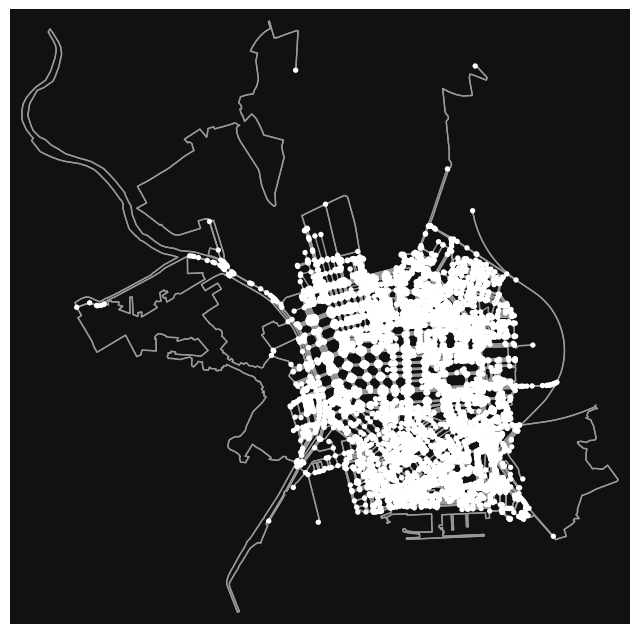

(<Figure size 800x800 with 1 Axes>,
 <Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>)

In [2]:
import osmnx as ox

G = ox.graph_from_xml("/kaggle/input/datasets/rubendelvalle/mapa-crt2/map2.osm", simplify=True)    # grafo de NetworkX
nodes, edges = ox.graph_to_gdfs(G)                  # a GeoDataFrames
ox.plot_graph(G)

In [3]:
%pip install folium

Note: you may need to restart the kernel to use updated packages.


In [4]:
%pip install folium mapclassify

Note: you may need to restart the kernel to use updated packages.


                    y         x   highway railway                   geometry
osmid                                                                       
4760010782  37.604880 -0.987920  crossing     NaN  POINT (-0.98792 37.60488)
4760010783  37.604972 -0.988457       NaN     NaN  POINT (-0.98846 37.60497)
4760010784  37.605255 -0.989428  crossing     NaN  POINT (-0.98943 37.60526)
2329935922  37.602579 -0.980900       NaN     NaN   POINT (-0.9809 37.60258)
3474849902  37.606980 -0.977477       NaN     NaN  POINT (-0.97748 37.60698)
...               ...       ...       ...     ...                        ...
4983357365  37.600208 -0.988050       NaN     NaN  POINT (-0.98805 37.60021)
4983357367  37.600249 -0.987676       NaN     NaN  POINT (-0.98768 37.60025)
4983357368  37.600251 -0.987578       NaN     NaN  POINT (-0.98758 37.60025)
4983357370  37.600262 -0.987266       NaN     NaN  POINT (-0.98727 37.60026)
3817471943  37.611341 -0.977782       NaN     NaN  POINT (-0.97778 37.61134)

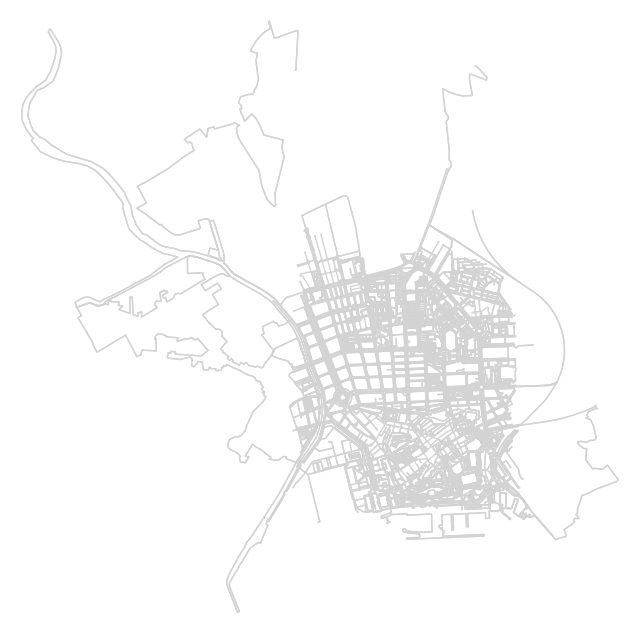

(<Figure size 800x800 with 1 Axes>,
 <Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>)

In [5]:
import osmnx as ox

# Cargar el mapa descargado
G = ox.graph_from_xml("/kaggle/input/datasets/rubendelvalle/mapa-crt2/map2.osm", simplify=True)
nodes, edges = ox.graph_to_gdfs(G)
print(nodes)
# a) Por coordenadas: el nodo de la red más cercano a cada punto que elijáis
#    (ojo: X = longitud, Y = latitud). Las coordenadas se sacan de Google Maps
#    o de openstreetmap.org con clic derecho.
lons = [-0.9865, -0.9790, -0.9912]
lats = [37.6050, 37.6102, 37.6001]
mis_nodos = ox.distance.nearest_nodes(G, X=lons, Y=lats)

# b) Por identificador: mapa interactivo donde, al pasar el ratón por un nodo,
#    se ve su id (osmid); apuntáis los que queráis.
nodes.explore()                    # en un notebook se muestra directamente
mis_nodos = [123456789, 987654321]  # ids de ejemplo: poned los vuestros

# Dibujar la red con los nodos elegidos resaltados
colores = ["red" if n in mis_nodos else "lightgray" for n in G.nodes]
tamanos = [40 if n in mis_nodos else 2 for n in G.nodes]
ox.plot_graph(G, node_color=colores, node_size=tamanos,
              edge_color="lightgray", bgcolor="white")

Nodos en la red: 8718
   id        nodo        lat       lon
0   1  3721796456  37.599614 -0.977941
1   2  2832211406  37.598578 -0.987990
2   3   767434546  37.615596 -0.982512
3   4   767434903  37.601354 -0.986862
4   5  3074184085  37.612072 -0.977395


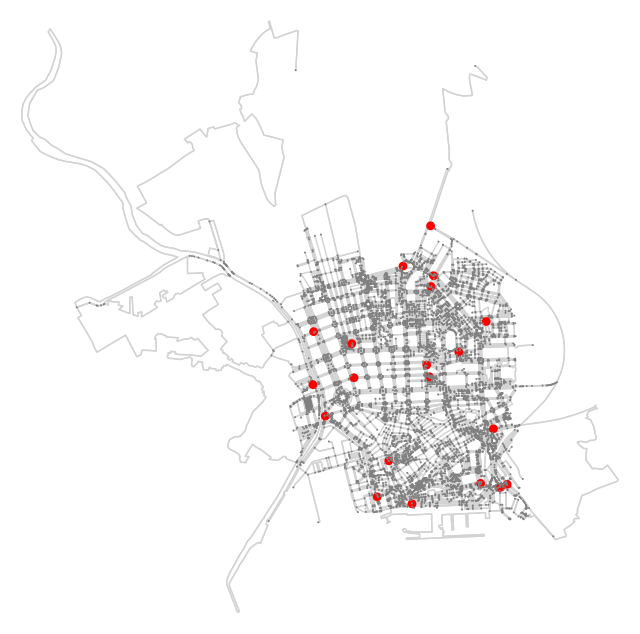

(<Figure size 800x800 with 1 Axes>,
 <Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>)

In [6]:
import random

import osmnx as ox
import pandas as pd

N_NODOS = 20          # cuántos nodos queréis
SEMILLA = 42           # misma semilla = misma selección cada vez (None para que cambie)

G = ox.graph_from_xml("/kaggle/input/datasets/rubendelvalle/mapa-crt2/map2.osm", simplify=True)
lista_nodos = list(G.nodes)                 # los ~6100 identificadores de nodo
print(f"Nodos en la red: {len(lista_nodos)}")

# 1) Elegir N_NODOS posiciones al azar con randint, sin repetir ninguna
random.seed(SEMILLA)
posiciones = set()
while len(posiciones) < N_NODOS:
    posiciones.add(random.randint(0, len(lista_nodos) - 1))   # randint incluye ambos extremos
mis_nodos = [lista_nodos[p] for p in sorted(posiciones)]

# 2) Recoger sus coordenadas en una tabla y guardarla
seleccion = pd.DataFrame({
    "id": range(1, N_NODOS + 1),
    "nodo": mis_nodos,                                  # identificador del nodo en OSM
    "lat": [G.nodes[n]["y"] for n in mis_nodos],        # y = latitud
    "lon": [G.nodes[n]["x"] for n in mis_nodos],        # x = longitud
})
seleccion.to_csv("nodos_seleccionados.csv", index=False)
print(seleccion.head())

# 3) Dibujar la red con los nodos elegidos en rojo
elegidos = set(mis_nodos)
colores = ["red" if n in elegidos else "gray" for n in G.nodes]
tamanos = [40 if n in elegidos else 2 for n in G.nodes]
ox.plot_graph(G, node_color=colores, node_size=tamanos, node_zorder=3,
              edge_color="lightgray", bgcolor="white")

In [8]:
# Matriz de distancias
import osmnx as ox
import networkx as nx
import numpy as np
import pandas as pd



nodos_rojos_ids = seleccion["nodo"].tolist()
etiquetas = seleccion["id"].tolist()  # para que la matriz final sea legible (1..20)


# 3. Matriz de distancias en metros (camino más corto por la red vial real)
n = len(nodos_rojos_ids)
matriz = np.full((n, n), np.inf)

for i, origen in enumerate(nodos_rojos_ids):
    distancias = nx.single_source_dijkstra_path_length(G, origen, weight="length")
    for j, destino in enumerate(nodos_rojos_ids):
        matriz[i, j] = distancias.get(destino, np.inf)

# 4. Convertir a DataFrame para verla cómoda y exportarla
df_matriz = pd.DataFrame(matriz, index=range(n), columns=range(n))
df_matriz.to_csv("matriz_distancias.csv")
print(df_matriz)

             0            1            2            3            4   \
0      0.000000  1101.852763  2085.947244  1039.788580  1555.979943   
1   1101.852763     0.000000  2436.686305   496.437428  2283.407348   
2   2101.683147  2425.980594     0.000000  2021.787094   711.036103   
3   1062.991249   493.940958  2030.754591     0.000000  1865.593152   
4   1546.048456  2251.998393   666.438047  1844.480928     0.000000   
5   1356.394238  1535.196150  1179.376712  1131.002649   902.979993   
6   2023.641844  2293.466890   454.732896  1889.273389   697.810193   
7    448.638411  1357.743355  2073.865849  1335.990151  1543.898548   
8   1409.925034  1874.404305   986.326724  1438.584892   557.621652   
9   1967.098053  1623.263462  1321.040861  1303.913563  1438.825937   
10   666.668085   470.390135  2499.556972   468.802381  2120.038210   
11  1760.156179   908.179200  2082.385054   784.950937  2011.967659   
12  2266.727837  2242.810583   313.027243  1838.617083   989.751404   
13  13

In [9]:
# Ir de un nodo a otro y ver el camino
import folium
import networkx as nx
import numpy as np
import osmnx as ox
from folium.plugins import AntPath

nodes, edges = ox.graph_to_gdfs(G)


def ir(a, b, weight="length"):
    """Va de la parada a a la parada b (ids 1..20 de `seleccion`) y dibuja el camino."""
    n_a = int(seleccion.loc[seleccion["id"] == a, "nodo"].iloc[0])
    n_b = int(seleccion.loc[seleccion["id"] == b, "nodo"].iloc[0])

    try:
        ruta = ox.routing.shortest_path(G, n_a, n_b, weight=weight)
    except nx.NetworkXNoPath:
        ruta = None
    if ruta is None:
        print(f"No hay camino de la parada {a} a la {b}.")
        return None

    # Geometría real de las calles recorridas (sigue las curvas)
    tramo = ox.routing.route_to_gdf(G, ruta, weight=weight)
    coords = [(lat, lon) for geom in tramo.geometry for lon, lat in geom.coords]
    metros = tramo["length"].sum()

    calles = tramo["name"].dropna().astype(str).nunique() if "name" in tramo else "-"
    print(f"Parada {a} -> parada {b}")
    print(f"  Distancia del camino:   {metros:,.0f} m")
    print(f"  Distancia en tu matriz: {matriz[a - 1, b - 1]:,.0f} m")
    print(f"  Nodos recorridos: {len(ruta)} | Calles distintas: {calles}")

    # Mapa
    m = folium.Map(location=[nodes["y"].mean(), nodes["x"].mean()],
                   zoom_start=14, tiles="OpenStreetMap")
    folium.GeoJson(edges[["geometry"]],
                   style_function=lambda f: {"color": "#bbbbbb", "weight": 1}).add_to(m)

    # Las 20 paradas en pequeño, para tener referencia
    for _, fila in seleccion.iterrows():
        folium.CircleMarker([fila["lat"], fila["lon"]], radius=4, color="#444",
                            fill=True, fill_opacity=0.8,
                            tooltip=f"Parada {int(fila['id'])}").add_to(m)

    # Camino recorrido (línea animada: se ve el sentido de la marcha)
    AntPath(coords, color="red", weight=6, delay=800,
            tooltip=f"{metros / 1000:.2f} km").add_to(m)

    for etiqueta, nodo, color in [(f"Origen (parada {a})", n_a, "green"),
                                  (f"Destino (parada {b})", n_b, "red")]:
        folium.Marker([G.nodes[nodo]["y"], G.nodes[nodo]["x"]],
                      tooltip=etiqueta, icon=folium.Icon(color=color)).add_to(m)

    m.fit_bounds(coords)   # encuadra el mapa en la ruta
    return m


# Probar: cambia los números por las paradas que quieras (1..20)
m = ir(1, 7)
m

Parada 1 -> parada 7
  Distancia del camino:   2,050 m
  Distancia en tu matriz: 2,050 m
  Nodos recorridos: 112 | Calles distintas: 9


In [19]:
# ---------- CAMIÓN: recorrido por varias tiendas ----------
import itertools
import folium
import networkx as nx
import numpy as np
import osmnx as ox
from folium.plugins import AntPath

nodes, edges = ox.graph_to_gdfs(G)


def coste_recorrido(paradas, volver=True):
    """Metros totales de un recorrido (ids 1..20), usando TU matriz."""
    p = list(paradas) + ([paradas[0]] if volver else [])
    return sum(matriz[a - 1, b - 1] for a, b in zip(p[:-1], p[1:]))


def mejor_orden(almacen, tiendas, volver=True):
    """Busca el orden de tiendas con menos metros. Sale y vuelve a `almacen`."""
    # Pocas tiendas (<=8): se prueban todas las combinaciones (resultado exacto)
    if len(tiendas) <= 8:
        mejor = min(itertools.permutations(tiendas),
                    key=lambda o: coste_recorrido([almacen, *o], volver))
        return [almacen, *mejor]

    # Muchas tiendas: vecino más cercano + mejoras 2-opt (muy buena aproximación)
    pendientes, orden = set(tiendas), [almacen]
    while pendientes:
        sig = min(pendientes, key=lambda t: matriz[orden[-1] - 1, t - 1])
        orden.append(sig)
        pendientes.remove(sig)
    mejorado = True
    while mejorado:
        mejorado = False
        for i in range(1, len(orden) - 1):
            for j in range(i + 1, len(orden)):
                nuevo = orden[:i] + orden[i:j + 1][::-1] + orden[j + 1:]
                if coste_recorrido(nuevo, volver) < coste_recorrido(orden, volver) - 1e-9:
                    orden, mejorado = nuevo, True
    return orden


def dibujar_recorrido(orden, volver=True, weight="length"):
    """Dibuja el recorrido completo del camión. `orden` = ids de parada, en orden."""
    paradas = list(orden) + ([orden[0]] if volver else [])
    nodo = lambda pid: int(seleccion.loc[seleccion["id"] == pid, "nodo"].iloc[0])

    m = folium.Map(location=[nodes["y"].mean(), nodes["x"].mean()],
                   zoom_start=14, tiles="OpenStreetMap")
    folium.GeoJson(edges[["geometry"]],
                   style_function=lambda f: {"color": "#bbbbbb", "weight": 1}).add_to(m)

    colores = ["red", "blue", "green", "purple", "orange", "darkred", "cadetblue", "black"]
    todas, total = [], 0
    for k, (a, b) in enumerate(zip(paradas[:-1], paradas[1:])):
        try:
            ruta = ox.routing.shortest_path(G, nodo(a), nodo(b), weight=weight)
        except nx.NetworkXNoPath:
            ruta = None
        if ruta is None:
            print(f"⚠ No hay camino de la parada {a} a la {b}")
            continue
        tramo = ox.routing.route_to_gdf(G, ruta, weight=weight)
        coords = [(lat, lon) for g in tramo.geometry for lon, lat in g.coords]
        metros = tramo["length"].sum()
        total += metros
        todas += coords
        AntPath(coords, color=colores[k % len(colores)], weight=6, delay=800,
                tooltip=f"Tramo {k + 1}: parada {a} → {b} ({metros / 1000:.2f} km)").add_to(m)
        print(f"Tramo {k + 1}: parada {a} → {b}: {metros:,.0f} m")

    for n, pid in enumerate(orden):
        etiqueta = "Almacén" if n == 0 else f"Tienda {n} (parada {pid})"
        texto = "A" if n == 0 else str(n)
        fondo = "#1a7f37" if n == 0 else "#222"
        folium.Marker(
            [G.nodes[nodo(pid)]["y"], G.nodes[nodo(pid)]["x"]], tooltip=etiqueta,
            icon=folium.DivIcon(html=f'<div style="background:{fondo};color:white;'
                                f'border-radius:50%;width:26px;height:26px;line-height:26px;'
                                f'text-align:center;font-weight:bold">{texto}</div>'),
        ).add_to(m)

    print(f"\nRecorrido: {' → '.join(map(str, paradas))}")
    print(f"Distancia total: {total / 1000:.2f} km")
    if todas:
        m.fit_bounds(todas)
    return m


# ===== A) Tú fijas el orden (el primero es el almacén) =====
#orden_fijo = [1, 5, 9, 12, 3]
#m = dibujar_recorrido(orden_fijo, volver=True)
#m

# ===== B) El programa busca el mejor orden =====
almacen = 1
tiendas = [2, 3,4 ,5 ,6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]
orden = mejor_orden(almacen, tiendas)
print("Orden óptimo:", orden)
print("Ahorro frente a tu orden:", coste_recorrido([almacen, *tiendas]) - coste_recorrido(orden), "m")
m = dibujar_recorrido(orden)
m

Orden óptimo: [1, 16, 8, 17, 14, 6, 9, 5, 3, 19, 13, 7, 10, 15, 18, 12, 4, 2, 11]
Ahorro frente a tu orden: 20031.200583816506 m
Tramo 1: parada 1 → 16: 413 m
Tramo 2: parada 16 → 8: 87 m
Tramo 3: parada 8 → 17: 635 m
Tramo 4: parada 17 → 14: 955 m
Tramo 5: parada 14 → 6: 344 m
Tramo 6: parada 6 → 9: 467 m
Tramo 7: parada 9 → 5: 558 m
Tramo 8: parada 5 → 3: 666 m
Tramo 9: parada 3 → 19: 565 m
Tramo 10: parada 19 → 13: 489 m
Tramo 11: parada 13 → 7: 481 m
Tramo 12: parada 7 → 10: 1,172 m
Tramo 13: parada 10 → 15: 414 m
Tramo 14: parada 15 → 18: 916 m
Tramo 15: parada 18 → 12: 609 m
Tramo 16: parada 12 → 4: 785 m
Tramo 17: parada 4 → 2: 494 m
Tramo 18: parada 2 → 11: 470 m
Tramo 19: parada 11 → 1: 667 m

Recorrido: 1 → 16 → 8 → 17 → 14 → 6 → 9 → 5 → 3 → 19 → 13 → 7 → 10 → 15 → 18 → 12 → 4 → 2 → 11 → 1
Distancia total: 11.19 km


In [20]:
# ---------- VEHÍCULOS: camión, bici, peatón (cada uno con sus vías permitidas) ----------
import itertools
import folium
import networkx as nx
import numpy as np
import osmnx as ox

# 0) ¿Qué tipos de vía trae tu mapa? (si no hay cycleway/path/footway, la bici no tiene caminos extra)
print(ox.graph_to_gdfs(G, nodes=False)["highway"].astype(str).value_counts().head(15))

COMUN = {"construction", "proposed", "razed", "abandoned", "elevator", "platform", "services", "rest_area"}
PERFILES = {
    "camion": {"excluir": COMUN | {"footway", "path", "pedestrian", "steps", "cycleway",
                                   "bridleway", "corridor", "track"},
               "vel_kmh": 30, "respeta_sentido": True, "color": "red", "grosor": 9},
    "bici":   {"excluir": COMUN | {"motorway", "motorway_link", "footway", "pedestrian",
                                   "steps", "corridor"},
               "vel_kmh": 15, "respeta_sentido": True, "color": "green", "grosor": 6},
    "peaton": {"excluir": COMUN | {"motorway", "motorway_link"},
               "vel_kmh": 5, "respeta_sentido": False, "color": "blue", "grosor": 3},
}


def construir_red(veh):
    """Copia de G con solo las vías que puede usar ese vehículo."""
    p = PERFILES[veh]
    Gv = G.copy()
    quitar = []
    for u, v, k, d in Gv.edges(keys=True, data=True):
        h = d.get("highway")
        tipos = set(h) if isinstance(h, list) else {h}
        if tipos & p["excluir"]:
            quitar.append((u, v, k))
    Gv.remove_edges_from(quitar)

    if not p["respeta_sentido"]:                      # peatón: puede ir en ambos sentidos
        nuevas = []
        for u, v, k, d in Gv.edges(keys=True, data=True):
            d2 = dict(d)
            if "geometry" in d2:
                d2["geometry"] = d2["geometry"].reverse()
            nuevas.append((v, u, d2))
        Gv.add_edges_from(nuevas)

    Gv = ox.truncate.largest_component(Gv, strongly=True)   # solo la parte conectada
    for u, v, k, d in Gv.edges(keys=True, data=True):
        d["tiempo"] = d["length"] / (p["vel_kmh"] / 3.6)    # segundos
    ids = np.array(list(Gv.nodes))
    xs = np.array([Gv.nodes[n]["x"] for n in ids])
    ys = np.array([Gv.nodes[n]["y"] for n in ids])
    return {"G": Gv, "ids": ids, "xs": xs, "ys": ys}


REDES = {veh: construir_red(veh) for veh in PERFILES}
for veh, R in REDES.items():
    print(f"{veh}: {R['G'].number_of_nodes()} nodos, {R['G'].number_of_edges()} tramos")


def nodo_parada(veh, pid):
    """Nodo de la red de ese vehículo para la parada pid (si no está, el más cercano)."""
    fila = seleccion.loc[seleccion["id"] == pid].iloc[0]
    R = REDES[veh]
    n = int(fila["nodo"])
    if n in R["G"]:
        return n
    d = ((R["xs"] - fila["lon"]) * np.cos(np.radians(fila["lat"]))) ** 2 + (R["ys"] - fila["lat"]) ** 2
    return int(R["ids"][np.argmin(d)])


def _mapa_base():
    nodes_, edges_ = ox.graph_to_gdfs(G)
    m = folium.Map(location=[nodes_["y"].mean(), nodes_["x"].mean()], zoom_start=14, tiles="OpenStreetMap")
    es_camino = edges_["highway"].astype(str).str.contains("footway|path|cycleway|track|pedestrian|steps")
    folium.GeoJson(edges_[~es_camino][["geometry"]],
                   style_function=lambda f: {"color": "#bbbbbb", "weight": 1}).add_to(m)
    if es_camino.any():     # caminos que no son carretera, en marrón discontinuo
        folium.GeoJson(edges_[es_camino][["geometry"]],
                       style_function=lambda f: {"color": "#a0522d", "weight": 1.5, "dashArray": "4"}).add_to(m)
    return m


def _camino(veh, a, b, weight):
    R = REDES[veh]
    na, nb = nodo_parada(veh, a), nodo_parada(veh, b)
    try:
        ruta = ox.routing.shortest_path(R["G"], na, nb, weight=weight)
    except nx.NetworkXNoPath:
        ruta = None
    if ruta is None:
        return None
    tramo = ox.routing.route_to_gdf(R["G"], ruta, weight=weight)
    coords = [(lat, lon) for g in tramo.geometry for lon, lat in g.coords]
    tipos = set()
    for h in tramo["highway"]:
        tipos |= set(h) if isinstance(h, list) else {h}
    return {"coords": coords, "metros": tramo["length"].sum(),
            "seg": tramo["tiempo"].sum(), "tipos": tipos, "na": na, "nb": nb}


def comparar(a, b, vehiculos=("camion", "bici", "peaton"), weight="tiempo"):
    """Dibuja el camino de a a b para cada vehículo, todos en el mismo mapa."""
    m = _mapa_base()
    todas = []
    for veh in vehiculos:
        r = _camino(veh, a, b, weight)
        if r is None:
            print(f"{veh}: no hay camino")
            continue
        p = PERFILES[veh]
        capa = folium.FeatureGroup(name=veh)
        folium.PolyLine(r["coords"], color=p["color"], weight=p["grosor"], opacity=0.8,
                        tooltip=f"{veh}: {r['metros']:,.0f} m, {r['seg'] / 60:.1f} min").add_to(capa)
        capa.add_to(m)
        todas += r["coords"]
        print(f"{veh:7s}: {r['metros']:>7,.0f} m | {r['seg'] / 60:>5.1f} min | vías: {', '.join(sorted(map(str, r['tipos'])))}")
    for pid, color in [(a, "green"), (b, "red")]:
        f = seleccion.loc[seleccion["id"] == pid].iloc[0]
        folium.Marker([f["lat"], f["lon"]], tooltip=f"Parada {pid}", icon=folium.Icon(color=color)).add_to(m)
    folium.LayerControl().add_to(m)
    if todas:
        m.fit_bounds(todas)
    return m


# ----- Recorrido con varias paradas para un vehículo concreto -----
def matriz_de(veh, weight="tiempo"):
    ids = [nodo_parada(veh, p) for p in seleccion["id"]]
    M = np.full((len(ids), len(ids)), np.inf)
    for i, o in enumerate(ids):
        d = nx.single_source_dijkstra_path_length(REDES[veh]["G"], o, weight=weight)
        for j, t in enumerate(ids):
            M[i, j] = d.get(t, np.inf)
    return M


def _coste(M, orden, volver):
    p = list(orden) + ([orden[0]] if volver else [])
    return sum(M[x - 1, y - 1] for x, y in zip(p[:-1], p[1:]))


def mejor_orden_v(M, almacen, tiendas, volver=True):
    if len(tiendas) <= 8:
        mejor = min(itertools.permutations(tiendas), key=lambda o: _coste(M, [almacen, *o], volver))
        return [almacen, *mejor]
    pend, orden = set(tiendas), [almacen]
    while pend:
        s = min(pend, key=lambda t: M[orden[-1] - 1, t - 1])
        orden.append(s)
        pend.remove(s)
    mejora = True
    while mejora:
        mejora = False
        for i in range(1, len(orden) - 1):
            for j in range(i + 1, len(orden)):
                nuevo = orden[:i] + orden[i:j + 1][::-1] + orden[j + 1:]
                if _coste(M, nuevo, volver) < _coste(M, orden, volver) - 1e-9:
                    orden, mejora = nuevo, True
    return orden


def recorrido_vehiculo(orden, veh, volver=True, weight="tiempo"):
    """Recorrido completo por las paradas de `orden` con el vehículo `veh`."""
    paradas = list(orden) + ([orden[0]] if volver else [])
    p = PERFILES[veh]
    m = _mapa_base()
    todas, tm, ts = [], 0, 0
    for k, (a, b) in enumerate(zip(paradas[:-1], paradas[1:])):
        r = _camino(veh, a, b, weight)
        if r is None:
            print(f"⚠ {veh}: no hay camino de {a} a {b}")
            continue
        tm += r["metros"]; ts += r["seg"]; todas += r["coords"]
        folium.PolyLine(r["coords"], color=p["color"], weight=5, opacity=0.8,
                        tooltip=f"Tramo {k + 1}: {a}→{b} ({r['metros']:,.0f} m)").add_to(m)
    for n, pid in enumerate(orden):
        f = seleccion.loc[seleccion["id"] == pid].iloc[0]
        folium.Marker([f["lat"], f["lon"]], tooltip="Almacén" if n == 0 else f"Tienda {n} (parada {pid})",
                      icon=folium.DivIcon(html=f'<div style="background:{"#1a7f37" if n == 0 else "#222"};'
                                          f'color:white;border-radius:50%;width:26px;height:26px;line-height:26px;'
                                          f'text-align:center;font-weight:bold">{"A" if n == 0 else n}</div>')).add_to(m)
    print(f"{veh}: {' → '.join(map(str, paradas))}")
    print(f"Total: {tm / 1000:.2f} km | {ts / 60:.1f} min")
    if todas:
        m.fit_bounds(todas)
    return m


# ===== Probar =====
# 1) Mismo trayecto con los tres vehículos (activa/desactiva capas con el control de arriba a la derecha)
m = comparar(1, 7)
m

highway
nan                     16868
footway                  8152
pedestrian               2016
residential              1452
service                   812
primary                   543
cycleway                  537
secondary                 515
tertiary                  327
living_street             311
steps                     152
construction               92
['steps', 'footway']       74
track                      56
primary_link               43
Name: count, dtype: int64
camion: 5052 nodos, 15049 tramos
bici: 5493 nodos, 16703 tramos
peaton: 8714 nodos, 63952 tramos
camion :   2,153 m |   4.3 min | vías: nan, primary, residential, secondary, service, tertiary
bici   :   2,126 m |   8.5 min | vías: cycleway, nan, primary, residential, secondary, service, tertiary
peaton :   2,022 m |  24.3 min | vías: footway, nan, pedestrian, primary, residential, secondary, tertiary, tertiary_link
